In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ART = Path("artifacts"); (ART / "models").mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
from sklearn.model_selection import GridSearchCV

In [2]:
meta = json.load(open(ART / "meta.json"))
METALS, CATS, TARGETS = meta["METALS"], meta["CATS"], meta["TARGETS"]
FEATURES = METALS + CATS
train = pd.read_csv(ART / "train.csv")
print(train.shape, "| years:", sorted(train["Year"].unique()))

(32, 14) | years: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)]


In [3]:
def build_pipeline(model):
    """Preprocessing + model, with the target standardised (helps SVR/Ridge when the target has a tiny scale)."""
    pre = ColumnTransformer([
        ("num", StandardScaler(), METALS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATS),
    ])
    return TransformedTargetRegressor(
        regressor=Pipeline([("pre", pre), ("model", model)]),
        transformer=StandardScaler(),
    )

def get_models():
    return {
        "Ridge":            Ridge(),
        "RandomForest":     RandomForestRegressor(random_state=RANDOM_STATE),
        "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "SVR":              SVR(),
    }

## 1. Parameter grids
Parameter names carry the `regressor__model__` prefix because the model sits inside the pipeline / target transformer.

In [4]:
P = "regressor__model__"
param_grids = {
    "Ridge": {P+"alpha": [1e-3, 1e-2, 0.1, 1, 10, 100]},
    "RandomForest": {P+"n_estimators": [100, 300],
                     P+"max_depth": [None, 3, 6],
                     P+"min_samples_leaf": [1, 2, 4],
                     P+"max_features": [1.0, 0.5]},
    "GradientBoosting": {P+"n_estimators": [100, 300],
                         P+"learning_rate": [0.03, 0.1],
                         P+"max_depth": [2, 3],
                         P+"subsample": [0.8, 1.0]},
    "SVR": {P+"C": [0.1, 1, 10, 100],
            P+"epsilon": [0.01, 0.05, 0.1, 0.2],
            P+"gamma": ["scale", 0.01, 0.1]},
}
{k: int(np.prod([len(v) for v in g.values()])) for k, g in param_grids.items()}   # number of combinations

{'Ridge': 6, 'RandomForest': 36, 'GradientBoosting': 16, 'SVR': 48}

## 2. Grid search (leave-one-year-out CV, scored by RMSE)

In [5]:
cv = GroupKFold(n_splits=train["Year"].nunique())
groups = train["Year"]
baseline_cv = pd.read_csv(ART / "baseline_cv.csv")

best_params, rows = {}, []
for target in TARGETS:
    X, y = train[FEATURES], train[target]
    best_params[target] = {}
    for name, model in get_models().items():
        gs = GridSearchCV(build_pipeline(model), param_grids[name], cv=cv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
        gs.fit(X, y, groups=groups)
        best_params[target][name] = {k.replace(P, ""): (v if not isinstance(v, np.generic) else v.item())
                                     for k, v in gs.best_params_.items()}
        base = baseline_cv.query("target == @target and model == @name")["CV_RMSE"].iloc[0]
        rows.append({"target": target, "model": name, "baseline_CV_RMSE": base,
                     "tuned_CV_RMSE": -gs.best_score_, "best_params": best_params[target][name]})
        joblib.dump(gs.best_estimator_, ART / "models" / f"tuned_{target}_{name}.joblib")
        print(f"{target:4s} {name:17s} baseline {base:.5f} -> tuned {-gs.best_score_:.5f}")

tuning = pd.DataFrame(rows)
tuning["improvement_%"] = 100 * (1 - tuning["tuned_CV_RMSE"] / tuning["baseline_CV_RMSE"])
tuning.to_csv(ART / "tuning_results.csv", index=False)
json.dump(best_params, open(ART / "best_params.json", "w"), indent=2)

HPI  Ridge             baseline 0.00053 -> tuned 0.00001
HPI  RandomForest      baseline 0.00223 -> tuned 0.00213
HPI  GradientBoosting  baseline 0.00179 -> tuned 0.00169
HPI  SVR               baseline 0.00270 -> tuned 0.00092
HEI  Ridge             baseline 0.01300 -> tuned 0.00027
HEI  RandomForest      baseline 0.06076 -> tuned 0.05506
HEI  GradientBoosting  baseline 0.06658 -> tuned 0.05448
HEI  SVR               baseline 0.04336 -> tuned 0.01207
DC   Ridge             baseline 0.01298 -> tuned 0.00027
DC   RandomForest      baseline 0.06137 -> tuned 0.05502
DC   GradientBoosting  baseline 0.06732 -> tuned 0.05618
DC   SVR               baseline 0.04336 -> tuned 0.01207


HPI  RandomForest      baseline 0.00223 -> tuned 0.00213


HPI  GradientBoosting  baseline 0.00179 -> tuned 0.00169


HPI  SVR               baseline 0.00270 -> tuned 0.00092


HEI  Ridge             baseline 0.01300 -> tuned 0.00027


...

HEI  SVR               baseline 0.04336 -> tuned 0.01207


DC   Ridge             baseline 0.01298 -> tuned 0.00027


DC   RandomForest      baseline 0.06137 -> tuned 0.05502


DC   GradientBoosting  baseline 0.06732 -> tuned 0.05618


DC   SVR               baseline 0.04336 -> tuned 0.01207


## 3. Did tuning help?

In [6]:
tuning.drop(columns="best_params").round(5)

,target,model,baseline_CV_RMSE,tuned_CV_RMSE,improvement_%
0,HPI,Ridge,0.00053,0.00001,98.93841
1,HPI,RandomForest,0.00223,0.00213,4.20567
2,HPI,GradientBoosting,0.00179,0.00169,5.22946
3,HPI,SVR,0.00270,0.00092,65.81804
4,HEI,Ridge,0.01300,0.00027,97.92860
5,HEI,RandomForest,0.06076,0.05506,9.39014
6,HEI,GradientBoosting,0.06658,0.05448,18.16626
7,HEI,SVR,0.04336,0.01207,72.15540
8,DC,Ridge,0.01298,0.00027,97.92647
9,DC,RandomForest,0.06137,0.05502,10.35353


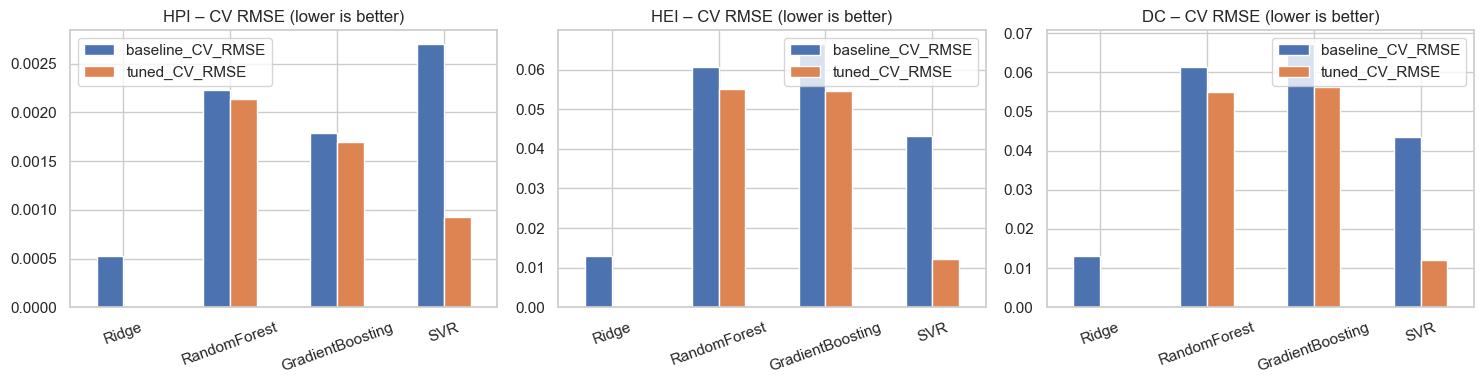

In [7]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(15, 4))
for ax, tgt in zip(axes, TARGETS):
    d = tuning[tuning.target == tgt].set_index("model")[["baseline_CV_RMSE", "tuned_CV_RMSE"]]
    d.plot.bar(ax=ax, rot=20); ax.set_title(f"{tgt} – CV RMSE (lower is better)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 4. Best model and parameters per target

In [8]:
best_per_target = tuning.loc[tuning.groupby("target")["tuned_CV_RMSE"].idxmin(), ["target", "model", "tuned_CV_RMSE", "best_params"]]
best_per_target.to_csv(ART / "best_model_per_target.csv", index=False)
for _, r in best_per_target.iterrows():
    print(f"{r.target}: {r.model}  (CV RMSE {r.tuned_CV_RMSE:.5f})  params = {r.best_params}")

DC: Ridge  (CV RMSE 0.00027)  params = {'alpha': 0.001}
HEI: Ridge  (CV RMSE 0.00027)  params = {'alpha': 0.001}
HPI: Ridge  (CV RMSE 0.00001)  params = {'alpha': 0.001}
